# Proyecto 3 — Mejorando algoritmos con CUDA: reconocimiento de ASL (versión CUDA)

CC3069 – Computación Paralela y Distribuida | Universidad del Valle de Guatemala

**Integrantes:** Pedro Avila · Brandon Rivera · Javier Lopez

Este notebook acelera con **CUDA** el entrenamiento de la `SmallCNN` del Laboratorio 3 (Data Science) y lo compara con la
línea base secuencial de `notebooks/asl_lab3.ipynb`.

* **Todo el cálculo de la red está escrito a mano**: cada capa es un kernel `@cuda.jit` propio (CUDA Python con Numba,
  archivo `src/cuda_kernels.py`). **No se usa PyTorch** para nada en este notebook (la última celda lo comprueba).
* **Separación estricta del pipeline** (criterio central del proyecto):
  * **CPU multinúcleo** → todo lo que toca archivos/imágenes: leer JPG, decodificar, redimensionar, partir, guardar.
  * **GPU (CUDA)** → *únicamente* la matemática de la red: forward, pérdida, backward y Adam.
* No se corre a mano: lo ejecuta `bash pruebas/inciso3_cuda.sh`, y la comparación final sale de
  `bash pruebas/inciso4_comparacion.sh`.

## Índice

1. Preparación del entorno
2. Identificación de oportunidades de paralelización
3. Diseño del algoritmo paralelo (hilos, bloques y grids)
4. Fase A — Preparación de datos en CPU multinúcleo
5. Fase B — Entrenamiento en GPU con kernels propios (compilación, transferencia, entrenamiento, evaluación)
6. Comparación con la versión secuencial: tablas, speedup y gráficos
7. Discusión técnica

## 1. Preparación del entorno

Se verifica que Numba vea la GPU y se leen los parámetros del experimento (`P3_*`), que son **los mismos** que usó el
benchmark secuencial.

In [1]:
import os, sys, json, time, inspect, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))
sys.path.insert(0, str(REPO_ROOT / "pruebas"))
os.chdir(REPO_ROOT)

import numba
from numba import cuda
import data_utils as du
import cuda_kernels as ck
from cuda_cnn import CudaSmallCNN
from bench_utils import cargar_config, RegistroFases

if not cuda.is_available():
    raise RuntimeError("Numba no detecta una GPU CUDA. Revisa el driver (nvidia-smi) y: pip install 'numba-cuda[cu12]' 'numpy<2.5'")

cfg = cargar_config("cuda")
dev = cuda.get_current_device()
_nombre = getattr(dev, "name", "desconocida")
_nombre = _nombre.decode() if isinstance(_nombre, bytes) else str(_nombre)
gpu_meta = {"nombre": _nombre,
            "compute_capability": list(getattr(dev, "compute_capability", ())),
            "multiprocesadores": getattr(dev, "MULTIPROCESSOR_COUNT", None),
            "max_hilos_por_bloque": getattr(dev, "MAX_THREADS_PER_BLOCK", None)}
try:
    libre, total = cuda.current_context().get_memory_info()
    if 0 < total < float("inf"):
        gpu_meta["memoria_total_mb"] = round(total / 2**20)
except Exception:
    pass

reg = RegistroFases(cfg, meta={"gpu": gpu_meta, "numba": numba.__version__, "dispositivo": "cuda"})
print("GPU:", gpu_meta)
print(cfg)

GPU: {'nombre': 'NVIDIA GeForce RTX 4070 Ti', 'compute_capability': [8, 9], 'multiprocesadores': 60, 'max_hilos_por_bloque': 1024, 'memoria_total_mb': 12282}
ConfigBench(etiqueta='cuda', arquitectura='SmallCNN', n_per_class=600, img_size=64, epochs=15, batch_size=128, lr=0.001, weight_decay=0.0001, seed=42, workers=16, seq_threads=1, rep=3, raw_dir='C:\\Users\\cr57b\\Documentos\\Proyecto_3_deep_learning\\data\\raw\\asl_alphabet_train\\asl_alphabet_train', processed_dir='C:\\Users\\cr57b\\Documentos\\Proyecto_3_deep_learning\\data\\processed\\bench_cuda', salida_dir='C:\\Users\\cr57b\\Documentos\\Proyecto_3_deep_learning\\pruebas\\resultados')


## 2. Identificación de oportunidades de paralelización

Se analizó cada operación de la solución secuencial (Tabla 1 de `asl_lab3.ipynb`, sección 12) con dos preguntas:
¿las unidades de trabajo son independientes entre sí? y ¿la operación es aritmética regular (sin ramas ni accesos a disco)?

| Operación | ¿Se paraleliza? | Tipo de paralelismo | Dónde corre | Justificación |
|---|---|---|---|---|
| Listar archivos y submuestrear | No | — | CPU | Metadatos del sistema de archivos; costo bajo y secuencial. |
| Leer + decodificar JPG + redimensionar | **Sí** | Datos: cada imagen es independiente | **CPU, N procesos** | La decodificación JPEG (Huffman) tiene mucha lógica de control y depende del disco; la GPU no accede a archivos. Imágenes independientes ⇒ reparto trivial entre núcleos, sin comunicación. |
| Partición estratificada, guardar/leer `.npz` | No | — | CPU | Barato y dominado por E/S (parte serial: ley de Amdahl). |
| `uint8 HWC → float32 CHW ÷255` del lote | **Sí** | Elemento a elemento | GPU (`k_preparar_lote`) | El dataset ya reside en VRAM como `uint8` (4× menos bytes que `float32`); convertir allí evita transferir el lote en cada paso. |
| Convolución 3×3 + ReLU (forward) | **Sí** | Cada píxel de salida es independiente | GPU (`k_conv3x3_relu`) | Es la operación de mayor costo (≈ 6.5 M de los 7.5 M MAC por imagen) y es aritmética regular. |
| Max-pool 2×2 | **Sí** | Ventanas disjuntas | GPU (`k_maxpool2`) | Cada salida depende solo de su ventana. |
| Capas lineales (GEMM) | **Sí** | Cada elemento de C es un producto punto | GPU (`k_gemm`, tiles en memoria compartida) | Reutilización de datos entre hilos del bloque. |
| ReLU + sesgo + dropout | **Sí** | Elemento a elemento | GPU (`k_bias_relu_dropout`) | Operaciones fusionadas en un solo recorrido de memoria; RNG propio por hilo. |
| Softmax + entropía cruzada | **Sí** (por muestra) | Una muestra por hilo | GPU (`k_softmax_ce`) | Poca carga, pero evita copiar los logits a la CPU en cada paso. |
| Backward de convoluciones | **Sí** | Reducción paralela (pesos) / por píxel (entrada) | GPU (`k_conv3x3_bwd_pesos`, `k_conv3x3_bwd_entrada`, `k_conv_bwd_sesgo`) | ~2/3 del costo de entrenar. |
| Actualización Adam | **Sí** | Un hilo por parámetro | GPU (`k_adam`) | Elemento a elemento. |
| Bucle de épocas y lotes | **No** | — | CPU solo orquesta | Cada paso usa los pesos que dejó el anterior (dependencia secuencial); la CPU únicamente lanza kernels. |

## 3. Diseño del algoritmo paralelo

**Datos residentes en GPU.** El conjunto de entrenamiento (`uint8`, ≈150 MB) se copia **una sola vez** a la VRAM; durante las
épocas no hay transferencias de imágenes. Por época solo viajan: la permutación de índices (CPU→GPU, 48 KB) y 2 contadores
(GPU→CPU). Los kernels se lanzan de forma asíncrona sobre el stream por defecto, así que la CPU no espera entre kernels.

**Mapeo de trabajo a hilos, bloques y grids** (layout NCHW, `float32`; `n` = tamaño real del lote):

| Kernel | Operación | 1 hilo calcula… | Bloque | Grid | Memoria |
|---|---|---|---|---|---|
| `k_preparar_lote` | gather + ÷255 + NHWC→NCHW | 1 valor del lote | 256 | `⌈n·C·H·W / 256⌉` | global |
| `k_conv3x3_relu` | convolución 3×3 + sesgo + ReLU | 1 píxel de salida de 1 canal | 16×16 | `(⌈W/16⌉, ⌈H/16⌉, n·C_out)` | global (pesos: broadcast) |
| `k_maxpool2` | max-pool 2×2 (guarda posición del máximo) | 1 valor de salida | 256 | `⌈n·C·H/2·W/2 / 256⌉` | global |
| `k_gemm` | C = A·B con strides (sirve también para transpuestas) | 1 elemento de C | 16×16 | `(⌈N/16⌉, ⌈M/16⌉)` | **compartida** (2 tiles 16×16) |
| `k_bias_relu_dropout` | sesgo + ReLU + dropout | 1 activación | 256 | `⌈n·F / 256⌉` | global |
| `k_softmax_ce` | softmax + entropía cruzada + ∂logits + aciertos | 1 muestra | ≤128 | 1 | global + `atomicAdd` |
| `k_dropout_relu_bwd` | ∂ de dropout y ReLU | 1 activación | 256 | `⌈n·F / 256⌉` | global |
| `k_pool_relu_bwd` | ∂ de max-pool y ReLU (gather, sin atómicas) | 1 píxel de entrada | 256 | `⌈n·C·H·W / 256⌉` | global |
| `k_conv3x3_bwd_pesos` | ∂ pesos de la convolución | **1 bloque = 1 peso**; 256 hilos reparten `n·H·W` términos | 256 | `C_out·C_in·9` | **compartida** (reducción en árbol) |
| `k_conv_bwd_sesgo` | ∂ sesgo de la convolución | 1 bloque = 1 canal | 256 | `C_out` | compartida |
| `k_conv3x3_bwd_entrada` | ∂ entrada de la convolución | 1 píxel de entrada | 16×16 | `(⌈W/16⌉, ⌈H/16⌉, n·C_in)` | global |
| `k_suma_columnas` | ∂ sesgo de capas densas | 1 columna | 256 | `⌈F/256⌉` | global |
| `k_adam` | Adam con *weight decay* L2 | 1 parámetro | 256 | `⌈params / 256⌉` | global |

**Decisiones de diseño.**
* *Fusión de kernels:* conv+ReLU, bias+ReLU+dropout y pool+ReLU(backward) comparten kernel para no escribir/leer
  resultados intermedios en memoria global.
* *Tiling en memoria compartida* en el GEMM (reutiliza cada dato 16 veces) y *reducción en árbol* para los gradientes de
  pesos de las convoluciones, que suman `n·H·W` términos.
* *Sin condiciones de carrera:* el backward del max-pool es un *gather* (cada hilo consulta su propio píxel), no un
  *scatter* con atómicas.
* *Dropout reproducible:* hash PCG por `(semilla, índice)`; evita transferir máscaras desde la CPU.
* *Sin `malloc` en el bucle:* todos los buffers se reservan una vez (`CudaSmallCNN.__init__`).
* *Corrección verificada:* `pruebas/verificar_kernels.py` compara logits, pérdida, los 8 gradientes y un paso de Adam contra
  PyTorch en CPU (solo como referencia numérica) antes de cada benchmark.

### Código de los kernels (escritos a mano)

In [2]:
def fuente(k):
    f = getattr(k, "py_func", None) or getattr(k, "fn", None) or k
    return inspect.getsource(f)

print(f"TILE={ck.TILE}  RED={ck.RED}  TPB={ck.TPB}\n")
for k in [ck._hash32] + ck.KERNELS:
    print(fuente(k))

TILE=16  RED=256  TPB=256

@cuda.jit(device=True)
def _hash32(semilla, i):
    """Entero pseudoaleatorio de 32 bits (hash PCG) a partir de (semilla, indice); solo aritmetica entera."""
    s = (int64(i) * 747796405 + int64(semilla) * 2891336453 + 2891336453) & 0xFFFFFFFF
    palabra = (((s >> ((s >> 28) + 4)) ^ s) * 277803737) & 0xFFFFFFFF
    return ((palabra >> 22) ^ palabra) & 0xFFFFFFFF

@cuda.jit
def k_preparar_lote(x_u8, idx, off, out, n, C, H, W):
    """out[b,c,y,x] = x_u8[idx[off+b], y, x, c] / 255.  (gather del lote + normalizacion)"""
    i = cuda.grid(1)
    if i < n * C * H * W:
        xw = i % W
        t = i // W
        yh = t % H
        t = t // H
        c = t % C
        b = t // C
        s = int64(idx[off + b])
        out[i] = float32(x_u8[((s * H + yh) * W + xw) * C + c]) / float32(255.0)

@cuda.jit
def k_conv3x3_relu(x, w, bias, out, n, cin, cout, H, W):
    """out[b,co,y,x] = ReLU(bias[co] + sum_{ci,ky,kx} x[b,ci,y+ky-1,x+kx-1] * w[co,ci,ky,kx])"""
    xo = c

## 4. Fase A — Preparación de datos en CPU multinúcleo

Aquí **no se usa la GPU**. Es la misma selección aleatoria, decodificación y redimensionado que la versión secuencial
(`du.build_subsample`), pero repartida entre `P3_WORKERS` procesos (`du.build_subsample_parallel`). Se comprueba que el
resultado es idéntico bit a bit.

In [3]:
carpeta = Path(cfg.processed_dir)
print(f"Procesos de preparación: {cfg.workers} (núcleos lógicos: {os.cpu_count()})")

with reg.fase("carga_resize", grupo="prep_datos"):
    X_all, y_all, names_all = du.build_subsample_parallel(cfg.n_per_class, cfg.img_size, cfg.seed, Path(cfg.raw_dir),
                                                          n_workers=cfg.workers)
with reg.fase("split_estratificado", grupo="prep_datos"):
    tr_idx, va_idx, te_idx = du.stratified_split(y_all, seed=cfg.seed)
with reg.fase("guardar_npz", grupo="prep_datos"):
    du.save_processed(X_all[tr_idx], y_all[tr_idx], [names_all[i] for i in tr_idx], "train", carpeta)
    du.save_processed(X_all[va_idx], y_all[va_idx], [names_all[i] for i in va_idx], "val", carpeta)
    du.save_processed(X_all[te_idx], y_all[te_idx], [names_all[i] for i in te_idx], "test", carpeta)
with reg.fase("leer_npz", grupo="prep_datos"):
    X_train, y_train, _ = du.load_processed("train", carpeta)
    X_val, y_val, _ = du.load_processed("val", carpeta)
    X_test, y_test, _ = du.load_processed("test", carpeta)

print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}, dtype={X_train.dtype}")

# ¿Es idéntico a lo que preparó la versión secuencial?
seq_dir = REPO_ROOT / "data" / "processed" / "bench_secuencial"
if (seq_dir / "train.npz").exists():
    Xs, ys, _ = du.load_processed("train", seq_dir)
    print("Datos de entrenamiento idénticos a la preparación secuencial:", bool(np.array_equal(Xs, X_train) and np.array_equal(ys, y_train)))
else:
    print("(aún no existe la preparación secuencial para comparar)")

Procesos de preparación: 16 (núcleos lógicos: 16)
[FASE] >>> carga_resize (prep_datos)


[FASE] <<< carga_resize: 1.882 s


[FASE] >>> split_estratificado (prep_datos)


[FASE] <<< split_estratificado: 0.002 s


[FASE] >>> guardar_npz (prep_datos)


[FASE] <<< guardar_npz: 6.017 s


[FASE] >>> leer_npz (prep_datos)


[FASE] <<< leer_npz: 0.787 s


train: (12180, 64, 64, 3), val: (2610, 64, 64, 3), test: (2610, 64, 64, 3), dtype=uint8


Datos de entrenamiento idénticos a la preparación secuencial: True


## 5. Fase B — Entrenamiento en GPU con kernels propios

### 5.1 Compilación JIT (una sola vez por proceso)
Numba compila los kernels en su primera llamada. Para no mezclar esa compilación con el tiempo de entrenamiento, se hace un
paso de calentamiento con un lote diminuto y se **reportan por separado** (no entra en los totales).

In [4]:
N_CLASSES = len(du.CLASSES)
with reg.fase("compilacion_jit", grupo="jit", en_total=False, sync=cuda.synchronize):
    net = CudaSmallCNN(n_classes=N_CLASSES, img_size=cfg.img_size, batch_max=cfg.batch_size, dropout=0.3, seed=cfg.seed)
    net.calentar_jit()
print(f"Parámetros entrenables: {net.n_parametros:,}   (models.SmallCNN: 1,057,533)")

[FASE] >>> compilacion_jit (jit)


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 96 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 8 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 2 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 16 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low oc

C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


[FASE] <<< compilacion_jit: 1.432 s


Parámetros entrenables: 1,057,533   (models.SmallCNN: 1,057,533)


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 16 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 2 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 18 will likely result in GPU under-utilization due to low o

### 5.2 Transferencia CPU → GPU
El único viaje de imágenes: los tres conjuntos, como `uint8` aplanado.

In [5]:
with reg.fase("transferencia_h2d", grupo="h2d", sync=cuda.synchronize):
    d_Xtr = cuda.to_device(np.ascontiguousarray(X_train).reshape(-1))
    d_ytr = cuda.to_device(y_train.astype(np.int32))
    d_Xva = cuda.to_device(np.ascontiguousarray(X_val).reshape(-1))
    d_yva = cuda.to_device(y_val.astype(np.int32))
    d_Xte = cuda.to_device(np.ascontiguousarray(X_test).reshape(-1))
    d_yte = cuda.to_device(y_test.astype(np.int32))
mb = (X_train.nbytes + X_val.nbytes + X_test.nbytes) / 2**20
print(f"Copiados {mb:.1f} MB a la VRAM")

[FASE] >>> transferencia_h2d (h2d)


[FASE] <<< transferencia_h2d: 0.049 s


Copiados 203.9 MB a la VRAM


### 5.3 Entrenamiento
Cada paso: `k_preparar_lote` → forward → `k_softmax_ce` → backward → 8 × `k_adam`. La CPU solo lanza kernels;
sincroniza una vez por época para leer pérdida y aciertos.

In [6]:
with reg.fase("entrenamiento", grupo="entrenamiento", sync=cuda.synchronize):
    hist_cuda = net.entrenar(d_Xtr, d_ytr, len(y_train), d_Xva, d_yva, len(y_val),
                             epochs=cfg.epochs, lr=cfg.lr, weight_decay=cfg.weight_decay,
                             batch_size=cfg.batch_size, seed=cfg.seed)

[FASE] >>> entrenamiento (entrenamiento)


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 16 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 10 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 25 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 8 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


epoch 1/15 train_loss=3.1262 train_acc=0.1121 val_loss=2.6310 val_acc=0.2441 (1.5s)


epoch 2/15 train_loss=2.4505 train_acc=0.2460 val_loss=2.0432 val_acc=0.3935 (1.4s)


... (9 outputs left out)

epoch 12/15 train_loss=0.8774 train_acc=0.6887 val_loss=0.6113 val_acc=0.8172 (1.5s)


epoch 13/15 train_loss=0.7992 train_acc=0.7242 val_loss=0.5991 val_acc=0.8123 (1.5s)


epoch 14/15 train_loss=0.7521 train_acc=0.7331 val_loss=0.5368 val_acc=0.8452 (1.5s)


epoch 15/15 train_loss=0.7404 train_acc=0.7347 val_loss=0.5478 val_acc=0.8218 (1.4s)
[FASE] <<< entrenamiento: 21.681 s


In [7]:
# Evidencia de uso de la GPU justo después de entrenar (los buffers siguen reservados en VRAM)
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True, timeout=15).stdout)
except Exception as e:
    print("nvidia-smi no disponible:", e)
try:
    libre, total = cuda.current_context().get_memory_info()
    if 0 < total < float("inf"):
        gpu_meta["memoria_usada_mb"] = round((total - libre) / 2**20)
        print(f"VRAM en uso: {gpu_meta['memoria_usada_mb']} MB de {round(total / 2**20)} MB")
except Exception:
    pass

Wed Nov 18 00:00:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4070 Ti   WDDM  |   00000000:01:00.0  On |                  N/A |
| 70%   76C    P2            246W /  285W |    3256MiB /  12282MiB |    100%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 5.4 Evaluación en test
El forward corre en GPU; las predicciones regresan a la CPU (transferencia GPU→CPU incluida en el tiempo).

In [8]:
with reg.fase("evaluacion_test", grupo="evaluacion", sync=cuda.synchronize):
    test_loss_cuda, test_acc_cuda, preds_cuda = net.evaluar(d_Xte, d_yte, len(y_test))
print(f"Test: loss={test_loss_cuda:.4f}  accuracy={test_acc_cuda:.4f}")

reg.meta["gpu"] = gpu_meta
reg.guardar(extra={"historial": hist_cuda, "test_loss": test_loss_cuda, "test_acc": test_acc_cuda,
                   "n_parametros": net.n_parametros})
display(pd.DataFrame(reg.fases)[["fase", "grupo", "en_total", "duracion_s"]])
print(f"TOTAL del pipeline CUDA (sin compilación JIT): {reg.total():.2f} s")

[FASE] >>> evaluacion_test (evaluacion)


[FASE] <<< evaluacion_test: 0.042 s


Test: loss=0.5573  accuracy=0.8234
[BENCH] resultados guardados en C:\Users\cr57b\Documentos\Proyecto_3_deep_learning\pruebas\resultados\crudo\cuda_rep3.json


,fase,grupo,en_total,duracion_s
0,carga_resize,prep_datos,True,1.882318
1,split_estratificado,prep_datos,True,0.001681
2,guardar_npz,prep_datos,True,6.017462
3,leer_npz,prep_datos,True,0.786556
4,compilacion_jit,jit,False,1.432232
5,transferencia_h2d,h2d,True,0.048743
6,entrenamiento,entrenamiento,True,21.680923
7,evaluacion_test,evaluacion,True,0.042276


TOTAL del pipeline CUDA (sin compilación JIT): 30.46 s


## 6. Comparación con la versión secuencial

Mismos datos, misma arquitectura, mismos hiperparámetros. **Speedup = t_secuencial / t_CUDA** por fase. El tiempo de CUDA
incluye la transferencia CPU↔GPU. Si ya corriste `inciso2_secuencial.sh`, aquí aparecen las tablas; las definitivas
(promedio de todas las repeticiones, con uso de recursos por fase) las genera `bash pruebas/inciso4_comparacion.sh`.

Repeticiones: secuencial = 3, CUDA = 3

| Fase | Secuencial (s) | CUDA (s) | Speedup |
|---|---:|---:|---:|
| Preparación de datos | 15.57 ± 0.12 | 8.68 ± 0.06 | 1.79× |
| · carga + decodificación + resize | 8.80 ± 0.21 | 1.86 ± 0.02 | 4.72× |
| · partición estratificada | 0.00 ± 0.00 | 0.00 ± 0.00 | 1.02× |
| · guardado .npz | 5.97 ± 0.09 | 6.03 ± 0.05 | 0.99× |
| · lectura .npz | 0.79 ± 0.02 | 0.79 ± 0.01 | 1.01× |
| Transferencia CPU→GPU (H2D) | — | 0.05 ± 0.00 | — |
| Entrenamiento | 200.57 ± 3.75 | 21.01 ± 0.58 | 9.55× |
| Evaluación en test | 1.57 ± 0.02 | 0.04 ± 0.00 | 36.98× |
| **TOTAL del pipeline** | 217.71 ± 3.67 | 29.78 ± 0.59 | 7.31× |
| **TOTAL sin preparación de datos** | 202.14 ± 3.77 | 21.10 ± 0.58 | 9.58× |

| Métrica | Secuencial (PyTorch CPU) | CUDA (kernels propios) |
|---|---:|---:|
| Accuracy de validación (última época) | 84.25% | 82.18% |
| Accuracy en test | 84.83% | 82.34% |

Tiempo por época: secuencial 13.31 s | CUDA 1.400 s | speedup 9.5x


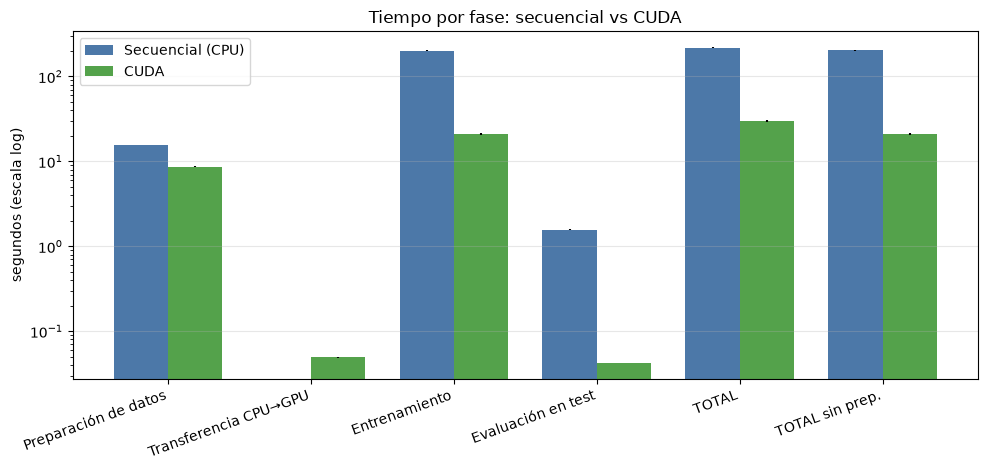

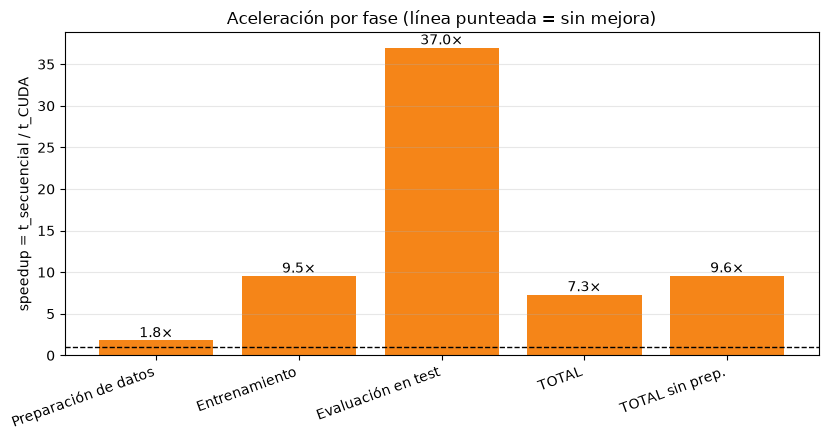

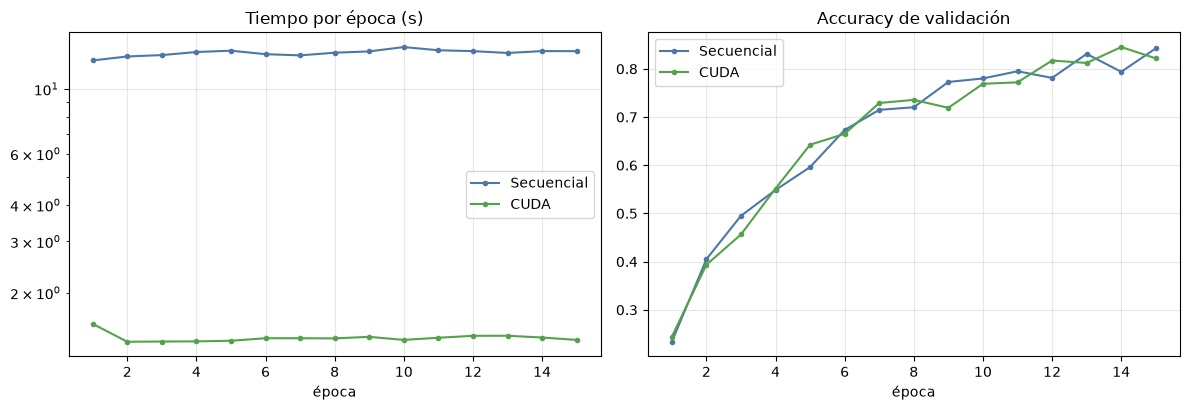

In [9]:
import generar_reporte as gr
from IPython.display import Markdown, display

seq_runs, cuda_runs = gr.cargar_runs("secuencial"), gr.cargar_runs("cuda")
if not seq_runs:
    print("Aún no hay resultados secuenciales. Ejecuta primero:  bash pruebas/inciso2_secuencial.sh")
else:
    df = gr.tabla_tiempos(seq_runs, cuda_runs)
    display(Markdown(f"Repeticiones: secuencial = {len(seq_runs)}, CUDA = {len(cuda_runs)}\n\n" + gr.md_tiempos(df)))
    display(Markdown(gr.md_calidad(seq_runs, cuda_runs)))
    ms, ss, mc, sc = gr.tabla_epocas(seq_runs, cuda_runs)
    if ms and mc:
        print(f"Tiempo por época: secuencial {ms:.2f} s | CUDA {mc:.3f} s | speedup {ms / mc:.1f}x")
    gr.fig_tiempos(df); plt.show()
    gr.fig_speedup(df); plt.show()
    gr.fig_epocas(seq_runs, cuda_runs); plt.show()

## 7. Discusión técnica

### ¿Por qué es más eficiente procesar las imágenes con los múltiples núcleos del CPU y delegar exclusivamente la matemática de la red neuronal al GPU?

* **La decodificación de imágenes no es el tipo de trabajo que favorece a la GPU.** Decodificar un JPEG (descompresión de
  Huffman, IDCT por bloques, conversión de color) está lleno de ramas y de dependencias entre símbolos consecutivos, y la
  GPU ejecuta hilos en bloques de 32 (*warps*) que pierden eficiencia cuando divergen. Los núcleos de CPU, en cambio, están
  hechos para lógica de control irregular.
* **La GPU no lee archivos.** Los bytes del disco pasan por el sistema operativo y la RAM sin importar qué procesador los
  use: el cuello de botella es E/S y *syscalls*, que son tareas de la CPU.
* **Las imágenes son independientes entre sí**, así que repartirlas entre procesos no requiere comunicación ni
  sincronización: el tiempo baja casi linealmente con los núcleos (hasta que el disco o la parte serial —listar, partir,
  guardar— lo limita).
* **Se procesa una sola vez y se reutiliza muchas.** Las imágenes se preparan una vez; la red las consume 15 épocas
  seguidas. Lo que se repite miles de veces (convoluciones, GEMM, retropropagación) es lo que compensa trasladar a la GPU.
* **Se transfiere lo mínimo.** Solo viajan por PCIe imágenes ya reducidas a 64×64 como `uint8`, una vez. Después todo
  ocurre dentro de la VRAM.
* **La matemática de la red es el caso ideal para SIMT:** miles de multiplicaciones-acumulaciones regulares, sin ramas y con
  acceso a memoria predecible.

### ¿Cómo CUDA permitió reducir o cambiar el tiempo de procesamiento?

* Una convolución produce `n·C_out·H·W` salidas independientes. En CUDA cada una es un hilo: cientos de miles de hilos
  en vuelo ocultan la latencia de memoria, algo que una CPU secuencial hace de a una (o unas pocas por SIMD).
* La **jerarquía grid → bloque → hilo** permitió mapear los tensores directamente: bloques 2-D de 16×16 sobre la imagen, grid
  3-D sobre lote×canales, bloques 1-D para elementos sueltos y un bloque por peso para las reducciones.
* La **memoria compartida** (tiles del GEMM y árbol de reducción) redujo los accesos a memoria global.
* La **fusión de kernels**, los **datos residentes en VRAM** y el **lanzamiento asíncrono** eliminaron viajes a la CPU:
  una sola sincronización por época.
* Cambió *dónde* está el costo: en CPU domina el entrenamiento; en GPU la fase de preparación (E/S, decodificación) pasa a
  ser una parte mucho más visible del total (ley de Amdahl). La sección 6 muestra los números medidos.

### ¿Qué factores justifican o limitan la utilización de CUDA?

| Justifican | Limitan |
|---|---|
| Alta intensidad aritmética y paralelismo de datos masivo (convoluciones, GEMM). | Parte serial que la GPU no acelera: listar/decodificar/guardar archivos y el bucle de lotes (Amdahl). |
| Muchas repeticiones del mismo cómputo (≈1,440 pasos): amortizan JIT y transferencia inicial. | Transferencias CPU↔GPU por PCIe y compilación JIT de la primera ejecución. |
| Datos que caben en VRAM y se reutilizan sin volver a la CPU. | Problema pequeño: lote de 128, imágenes 64×64 y una CNN chica no saturan una GPU grande (la capa final usa 1 bloque). |
| Operaciones sin ramas ni dependencias entre elementos. | Kernels propios sin las optimizaciones de cuDNN (Tensor Cores, Winograd/FFT): la convolución directa está limitada por memoria. |
| | VRAM limitada, solo hardware NVIDIA y depuración más difícil; reducciones y atómicas cambian el orden de suma, por lo que los resultados no son idénticos bit a bit a CPU. |

### Funciones y librerías adicionales que permiten trabajar con la GPU

| Componente | Para qué se usó |
|---|---|
| `numba.cuda` (`cuda.jit`, `cuda.grid`, `threadIdx/blockIdx`, `cuda.shared.array`, `cuda.syncthreads`, `cuda.atomic.add`) | Escribir los kernels y expresar la jerarquía de hilos, la memoria compartida y la sincronización. |
| `cuda.to_device`, `cuda.device_array`, `copy_to_host`, `copy_to_device`, `cuda.synchronize` | Reservar memoria en VRAM, transferir datos y medir con la GPU realmente terminada. |
| NVVM / `numba-cuda` → PTX → driver de NVIDIA (`cuda-bindings`, `cuda-pathfinder`) | Compilar los kernels a PTX y cargarlos con la API del driver. |
| `nvidia-smi` y `psutil` (`pruebas/monitor_recursos.py`) | Evidencia de uso de GPU (utilización, VRAM) y de CPU por núcleo en cada fase. |
| `concurrent.futures.ProcessPoolExecutor` (+ Pillow, NumPy) | Preparación de imágenes en varios núcleos de CPU, fuera de la GPU. |

In [10]:
# Comprobación final: este notebook no usó PyTorch en ningún momento.
print("PyTorch importado en este notebook:", "torch" in sys.modules)

PyTorch importado en este notebook: False
